# 03 · Did the emails work?

Pre-specified in `docs/analysis_plan.md`:
- **Primary metric:** revenue per customer (Welch's t-test, bootstrap 95% CI, Holm correction across H1 and H2).
- **Success:** Holm-adjusted p < 0.05 **and** the CI is entirely above $0.
- **Secondary:** conversion and visit rates. **Exploratory:** Mens vs Womens (H3).

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import ab_test as ab

pd.set_option("display.float_format", "{:,.4f}".format)
ab.apply_chart_style()

In [3]:
engine = ab.get_engine()
df = ab.load_clean(engine)
df.shape

MySQL password for root:  ········


(64000, 13)

## 1. Group summary (KPI tree)

In [4]:
summary = ab.group_summary(df)
summary.round(3)

,customers,visit_rate,conversion_rate,revenue_per_customer,spend_per_buyer
test_group,,,,,
Control,21306,10.6170,0.5730,0.6530,114.0030
Mens,21307,18.2760,1.2530,1.4230,113.5270
Womens,21387,15.1400,0.8840,1.0770,121.8950


- Revenue per customer: Control $0.65, Mens $1.42, Womens $1.08.
- **Revenue per customer = conversion × spend per buyer.** For Mens: 1.253% × $113.53 = $1.42. The Mens email more than doubled conversion while spend per buyer stayed flat.
- Spend per buyer is a diagnostic only: it rests on 120–270 buyers per group and is not tested.

## 2. Primary metric: revenue per customer (H1, H2)

In [5]:
rng = np.random.default_rng(ab.BOOTSTRAP_SEED)    # one seeded generator: same intervals every run
primary = ab.primary_results(df, rng)
primary.round(4)

,group,control_$,treated_$,lift_$,lift_%,ci_low_$,ci_high_$,p_value,p_holm,success
0,Mens,0.6528,1.4226,0.7698,117.9289,0.4864,1.0583,0.0000,0.0000,True
1,Womens,0.6528,1.0772,0.4244,65.0152,0.1717,0.6817,0.0011,0.0011,True


**Both emails meet the success criteria.**

| Email | Lift per customer | 95% CI | Holm p |
|---|---|---|---|
| Mens | +$0.77 (+118%) | $0.49 to $1.06 | < 0.0001 |
| Womens | +$0.42 (+65%) | $0.17 to $0.68 | 0.001 |

## 3. Secondary metrics: conversion and visits

In [6]:
secondary = ab.secondary_results(df)
secondary.round(4)

,metric,group,control_%,treated_%,lift_pp,ci_low_pp,ci_high_pp,p_value,p_holm
0,conversion,Mens,0.5726,1.2531,0.6805,0.5014,0.8641,0.0000,0.0000
1,conversion,Womens,0.5726,0.8837,0.3111,0.1502,0.4745,0.0002,0.0002
2,visit,Mens,10.6167,18.2757,7.6590,6.9953,8.3227,0.0000,0.0000
3,visit,Womens,10.6167,15.1400,4.5233,3.8894,5.1574,0.0000,0.0000


Both emails moved the whole funnel: more visits, then more purchases. Mens: conversion +0.68 percentage points (0.57% → 1.25%), visits +7.7 pp.

## 4. Mens vs Womens (H3, exploratory)

The two CIs above overlap, so the emails must be compared directly before calling a winner.

In [7]:
h3 = ab.mens_vs_womens(df, rng)
h3.round(4)

,comparison,diff_$,ci_low_$,ci_high_$,p_value
0,Mens minus Womens,0.3454,0.0275,0.6561,0.0305


The Mens email earns **$0.35 more per customer** (95% CI $0.03 to $0.66, p = 0.03). It is likely better, but the size of the gap is uncertain.

## 5. Business impact

In [8]:
impact = pd.DataFrame({
    "group": primary["group"],
    "extra_revenue_per_1000_emails_$": primary["lift_$"] * 1000,
    "low_$": primary["ci_low_$"] * 1000,
    "high_$": primary["ci_high_$"] * 1000,
})
impact.round(0)

,group,extra_revenue_per_1000_emails_$,low_$,high_$
0,Mens,770.0000,486.0000,"1,058.0000"
1,Womens,424.0000,172.0000,682.0000


## 6. Charts

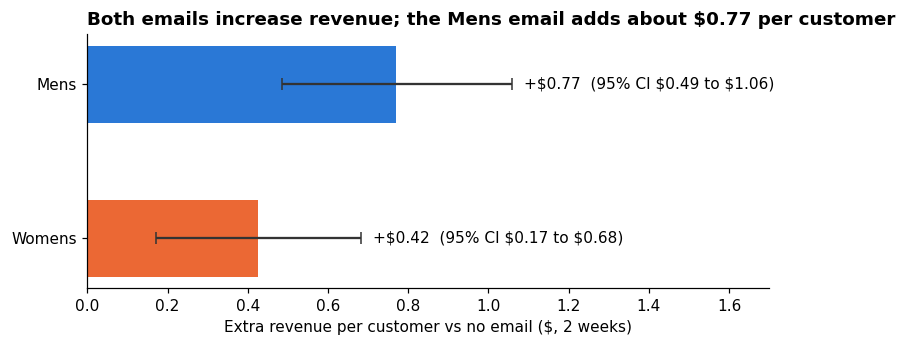

In [9]:
r = primary.set_index("group").loc[["Womens", "Mens"]]
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(r.index, r["lift_$"], color=[ab.COLORS[g] for g in r.index], height=0.5)
ax.errorbar(r["lift_$"], range(len(r)),
            xerr=[r["lift_$"] - r["ci_low_$"], r["ci_high_$"] - r["lift_$"]],
            fmt="none", ecolor="#333", capsize=4)
for y, (v, lo, hi) in enumerate(zip(r["lift_$"], r["ci_low_$"], r["ci_high_$"])):
    ax.text(hi + 0.03, y, f"+${v:.2f}  (95% CI ${lo:.2f} to ${hi:.2f})", va="center")
ax.set_xlim(0, 1.7)
ax.set_xlabel("Extra revenue per customer vs no email ($, 2 weeks)")
ax.set_title("Both emails increase revenue; the Mens email adds about $0.77 per customer")
ab.save_figure(fig, "01_revenue_lift.png")
plt.show()

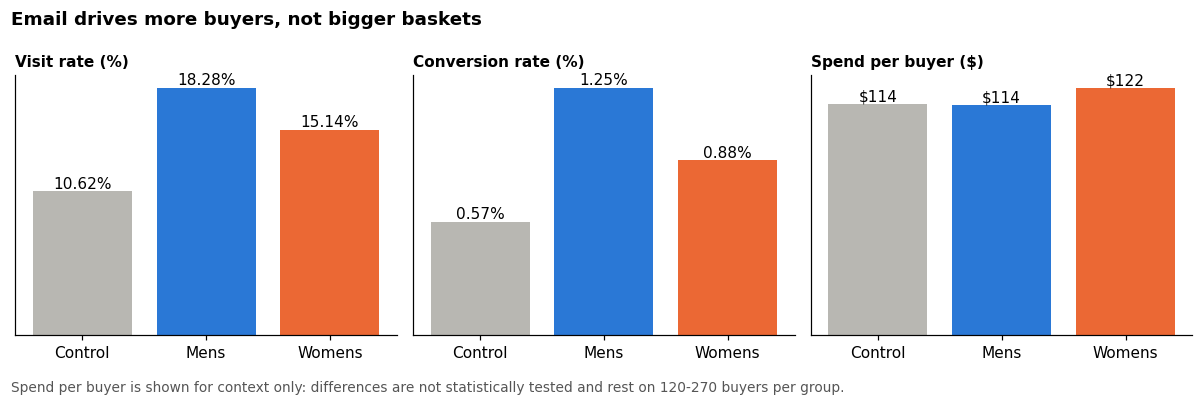

In [10]:
order = ["Control", "Mens", "Womens"]
metrics = [("visit_rate", "Visit rate (%)"), ("conversion_rate", "Conversion rate (%)"),
           ("spend_per_buyer", "Spend per buyer ($)")]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (col, label) in zip(axes, metrics):
    values = summary.loc[order, col]
    ax.bar(order, values, color=[ab.COLORS[g] for g in order])
    for x, v in enumerate(values):
        ax.text(x, v, f"${v:.0f}" if col == "spend_per_buyer" else f"{v:.2f}%", ha="center", va="bottom")
    ax.set_title(label, fontsize=10)
    ax.set_yticks([])
fig.suptitle("Email drives more buyers, not bigger baskets", x=0.01, ha="left", fontweight="bold")
fig.text(0.01, -0.04, "Spend per buyer is shown for context only: differences are not statistically "
         "tested and rest on 120-270 buyers per group.", fontsize=9, color="#555")
fig.tight_layout()
ab.save_figure(fig, "02_funnel.png")
plt.show()

## 7. Save results

In [11]:
ab.save_tables({
    "result_group_summary": summary.reset_index(),
    "result_primary_revenue": primary,
    "result_secondary_metrics": secondary,
    "result_h3_mens_vs_womens": h3,
}, engine)

result_group_summary           3 rows saved
result_primary_revenue         2 rows saved
result_secondary_metrics       4 rows saved
result_h3_mens_vs_womens       1 rows saved
